Jeg importerer bibliotekene som brukes i analysen og leser inn datasettet.

In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [29]:
df = pd.read_excel(
    "ICH AVCH 17-23u - final - anonymized - unif + imagistic.xlsx",
    sheet_name="ICH 17-23"
)

Jeg undersøker først størrelsen og strukturen på datasettet.

In [30]:
df.shape

(680, 72)

Datasettet inneholder 680 pasientregistreringer og 72 variabler.

In [31]:
df.head()

,Sectia externare,FO,Name,CNP,pacientID,L-hem,l-hem,h -hem,Vol-Hem,hVol Size,...,HEPATITA,Diabet,Trombocitopenie,Unnamed: 65,Blend Sign,Black Hold Sign/Swirls sign,Irregular Shape Sign,Satelite Sign,SUM_IMG,Progresie
0,Neurologie,704,anonymized,-,2465,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Neurologie,1217,anonymized,-,2641,NaN,NaN,NaN,NaN,NaN,...,C,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Neurologie,18984,anonymized,-,4228,29,25,25,9.0625,Small,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Neurologie,20066,anonymized,-,4228,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Neurologie,3163,anonymized,-,5379,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN


In [32]:
df.columns.tolist()

['Sectia externare',
 'FO',
 'Name',
 'CNP',
 'pacientID',
 'L-hem',
 'l-hem',
 'h -hem',
 'Vol-Hem',
 'hVol Size',
 'infratentorial',
 'IVH',
 'LOCALIZARE',
 'DataInternare',
 'YESta externarii',
 'Zile Spitalizare',
 'varsta',
 'grup varsta',
 'Sex',
 'Mediu',
 'DenStareExternare',
 'Diagnostic trimitere',
 'Diagnostic internare',
 'Diagnostice principale',
 'Diagnostic secunYESre',
 'Proceduri efectuate',
 'CodProcedura2011',
 'DenProcedura',
 'YEStaICP',
 'DenMedic',
 'Tratament efectuat',
 'Epicriza nr litere',
 'Epicriza',
 'Recomandari',
 'Examen_clinic_general',
 'Motiv_internare',
 'Istoricul_boli',
 'Examen_obiectiv',
 'Examene_radiologice',
 'EKG',
 'Examene_ecografice',
 'Examene_anatomo_patologice',
 'Alte_examene_de_specialitate',
 'Anamneza',
 'Antecedente_personale_patologice',
 'Antecedente_personale_fiziologice',
 'Descrierea_Interventiei_Chirugicale',
 'Evolutie',
 'CazID',
 'pacientID.1',
 'OPERAT ',
 'Eligibil',
 'Anticoagulant',
 'Antiagregant',
 'Statin',
 'GCS',

Pasienter markert med NO i variabelen Eligibil oppfylte ikke inklusjonskriteriene og filtreres derfor bort.

In [33]:
df_eligible = df[df["Eligibil"].isna()].copy()

In [34]:
df_eligible.shape

(601, 72)

Etter filtreringen står jeg igjen med 601 pasienter som inngår i analysen.

Utfallet i problemstillingen er mortalitet under sykehusoppholdet. Jeg lager derfor en binær variabel der 1 betyr at pasienten døde, og 0 betyr at pasienten overlevde.

In [35]:
df_eligible["mortalitet"] = (
    df_eligible["DenStareExternare"] == "Decedat"
).astype(int)

In [36]:
df_eligible["mortalitet"].value_counts()

mortalitet
0    423
1    178
Name: count, dtype: int64

Av de 601 pasientene døde 178 under sykehusoppholdet, mens 423 overlevde.

I tråd med problemstillingen bruker jeg alder, GCS, hematomvolum og IVH som inputvariabler, med mortalitet som utfallsvariabel.

In [37]:
analyse = df_eligible[
    ["varsta", "GCS", "Vol-Hem", "IVH", "mortalitet"]
].copy()

In [38]:
analyse.head()

,varsta,GCS,Vol-Hem,IVH,mortalitet
0,51,15.0,NaN,NO,0
1,65,14.0,NaN,NaN,0
2,78,15.0,9.0625,NO,0
3,78,14.0,NaN,NO,0
4,72,4.0,NaN,YES,1


Jeg undersøker manglende verdier i de valgte variablene før videre analyse.

In [39]:
analyse.isna().sum()

varsta          0
GCS           136
Vol-Hem       159
IVH            55
mortalitet      0
dtype: int64

Det mangler data for GCS, hematomvolum og IVH, mens alder og mortalitet er komplette.

Jeg kontrollerer datatyper og kategorier før videre analyse.

In [40]:
analyse["IVH"].value_counts(dropna=False)

IVH
NO      305
YES     240
NaN      55
?YES      1
Name: count, dtype: int64

In [41]:
analyse.dtypes

varsta          int64
GCS           float64
Vol-Hem        object
IVH               str
mortalitet      int64
dtype: object

IVH inneholder én verdi registrert som ?YES. Denne standardiseres til YES.

In [42]:
analyse["IVH"] = analyse["IVH"].replace("?YES", "YES")

analyse["IVH"].value_counts(dropna=False)

IVH
NO     305
YES    241
NaN     55
Name: count, dtype: int64

Hematomvolum er lest som tekst og konverteres derfor til numerisk format.

In [43]:
analyse["Vol-Hem"] = pd.to_numeric(
    analyse["Vol-Hem"],
    errors="coerce"
)

In [44]:
analyse.dtypes

varsta          int64
GCS           float64
Vol-Hem       float64
IVH               str
mortalitet      int64
dtype: object

In [45]:
analyse.head()

,varsta,GCS,Vol-Hem,IVH,mortalitet
0,51,15.0,NaN,NO,0
1,65,14.0,NaN,NaN,0
2,78,15.0,9.0625,NO,0
3,78,14.0,NaN,NO,0
4,72,4.0,NaN,YES,1


For å gjøre koden lettere å lese gir jeg variablene kortere norske navn.

In [46]:
analyse = analyse.rename(columns={
    "varsta": "alder",
    "GCS": "gcs",
    "Vol-Hem": "hematomvolum",
    "IVH": "ivh"
})

### Deskriptiv analyse.
Jeg beskriver alder, GCS og hematomvolum etter utfall, og undersøker fordelingen av IVH.

In [47]:
analyse.groupby("mortalitet")[
    ["alder", "gcs", "hematomvolum"]
].agg(
    ["count", "mean", "median", "std"]
).round(1)

alder                      gcs                   hematomvolum  \
           count  mean median   std count  mean median  std        count   
mortalitet                                                                 
0            423  68.4   69.0  11.7   288  13.0   14.0  2.9          311   
1            178  68.3   69.0  12.7   177   6.6    5.0  3.8          131   

                               
            mean median   std  
mortalitet                     
0           18.9    9.9  25.8  
1           57.8   38.9  57.3

For IVH ser jeg på antall og prosentandel overlevende og døde.

In [48]:
ivh_tabell = pd.crosstab(
    analyse["ivh"],
    analyse["mortalitet"]
).rename(
    columns={0: "Overlevde", 1: "Døde"}
)

ivh_tabell

mortalitet,Overlevde,Døde
ivh,,
NO,260,45
YES,119,122


Jeg beregner også prosentfordelingen innen hver IVH-gruppe.

In [49]:
ivh_prosent = pd.crosstab(
    analyse["ivh"],
    analyse["mortalitet"],
    normalize="index"
) * 100

ivh_prosent = ivh_prosent.rename(
    columns={0: "Overlevde", 1: "Døde"}
)

ivh_prosent.round(1)

mortalitet,Overlevde,Døde
ivh,,
NO,85.2,14.8
YES,49.4,50.6


Hematomvolum har enkelte høye ekstremverdier. I boksplottet skjules disse for å gjøre figuren lettere å lese, men verdiene beholdes i datasettet.

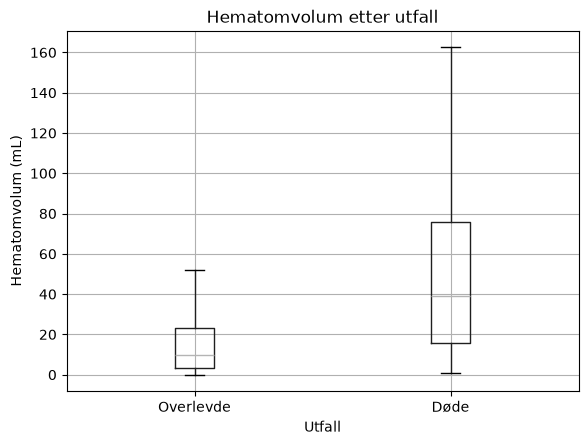

In [50]:
analyse.boxplot(
    column="hematomvolum",
    by="mortalitet",
    showfliers=False
)

plt.suptitle("")
plt.title("Hematomvolum etter utfall")
plt.xlabel("Utfall")
plt.ylabel("Hematomvolum (mL)")
plt.xticks([1, 2], ["Overlevde", "Døde"])
plt.show()

### Klargjøring av data til modellen.
Til modellen bruker jeg pasienter med komplette data for alder, GCS, hematomvolum, IVH og mortalitet. Rader med manglende verdier ekskluderes.

In [52]:
modell_data = analyse.dropna(
    subset=["alder", "gcs", "hematomvolum", "ivh", "mortalitet"]
).copy()

modell_data.shape

(349, 5)

In [53]:
modell_data["mortalitet"].value_counts()

mortalitet
0    220
1    129
Name: count, dtype: int64

IVH kodes som 0 for NO og 1 for YES før variabelen brukes i modellen.

In [54]:
modell_data["ivh"] = modell_data["ivh"].map({
    "NO": 0,
    "YES": 1
})

In [37]:
modell_data["ivh"].value_counts()

ivh
0    199
1    150
Name: count, dtype: int64

In [38]:
modell_data.head()

,alder,gcs,hematomvolum,ivh,mortalitet
2,78,15.0,9.0625,0,0
7,62,15.0,0.5400,1,0
10,62,13.0,11.7990,1,1
16,68,3.0,34.9125,1,1
21,67,15.0,3.7800,0,0


Alder, GCS, hematomvolum og IVH brukes som inputvariabler (X), mens mortalitet brukes som utfallsvariabel (y).

In [55]:
X = modell_data[
    ["alder", "gcs", "hematomvolum", "ivh"]
]

y = modell_data["mortalitet"]

### Trening av logistisk regresjonsmodell
Dataene deles i 80 % treningsdata og 20 % testdata. Stratifisering brukes for å bevare omtrent samme fordeling av mortalitet i begge settene.

In [56]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [57]:
print("Treningssett:", X_train.shape)
print("Testsett:", X_test.shape)

Treningssett: (279, 4)
Testsett: (70, 4)


In [58]:
print("Mortalitet i treningssett:")
print(y_train.value_counts(normalize=True).round(2))

print("\nMortalitet i testsett:")
print(y_test.value_counts(normalize=True).round(2))

Mortalitet i treningssett:
mortalitet
0    0.63
1    0.37
Name: proportion, dtype: float64

Mortalitet i testsett:
mortalitet
0    0.63
1    0.37
Name: proportion, dtype: float64


Jeg bruker logistisk regresjon fordi utfallet har to kategorier og modellen er relativt enkel å tolke. Inputvariablene standardiseres før modellen trenes.

In [59]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

modell = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)

modell.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](4,)","['alder','gcs','hematomvolum','ivh']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,4
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [60]:
y_pred = modell.predict(X_test)

### Evaluering av modellen
Jeg bruker confusion matrix, accuracy, sensitivitet og spesifisitet for å evaluere klassifiseringen.

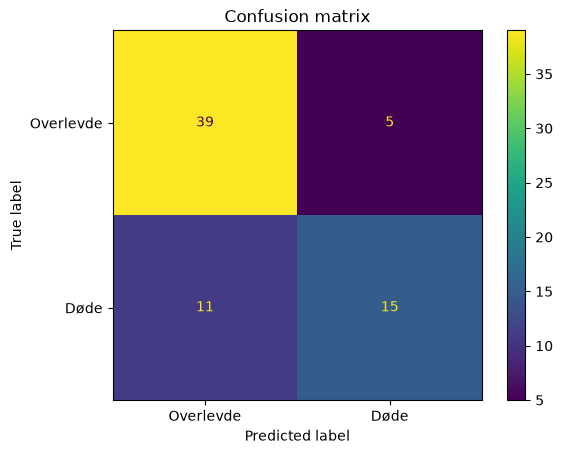

In [61]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay


cm = confusion_matrix(y_test, y_pred)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Overlevde", "Døde"]
)

display.plot()
plt.title("Confusion matrix")
plt.show()

In [62]:
from sklearn.metrics import accuracy_score, recall_score

accuracy = accuracy_score(y_test, y_pred)
sensitivitet = recall_score(y_test, y_pred)

tn, fp, fn, tp = cm.ravel()
spesifisitet = tn / (tn + fp)

print(f"Accuracy: {accuracy * 100:.1f} %")
print(f"Sensitivitet: {sensitivitet * 100:.1f} %")
print(f"Spesifisitet: {spesifisitet * 100:.1f} %")

Accuracy: 77.1 %
Sensitivitet: 57.7 %
Spesifisitet: 88.6 %


### Koeffisienter
Jeg undersøker de standardiserte koeffisientene for å se retningen og den relative størrelsen på variablenes bidrag i modellen.

In [63]:
logistisk_modell = modell.named_steps["logisticregression"]

koeffisienter = pd.DataFrame({
    "Variabel": X.columns,
    "Koeffisient": logistisk_modell.coef_[0]
})

koeffisienter["Absolutt verdi"] = koeffisienter["Koeffisient"].abs()

koeffisienter = koeffisienter.sort_values(
    "Absolutt verdi",
    ascending=False
)

koeffisienter

,Variabel,Koeffisient,Absolutt verdi
1,gcs,-1.692226,1.692226
3,ivh,0.491730,0.491730
2,hematomvolum,0.432114,0.432114
0,alder,0.122561,0.122561


## Kryssvalidering
Jeg gjennomfører 5-fold stratifisert kryssvalidering for å undersøke modellens ytelse på tvers av ulike oppdelinger av datasettet.

In [64]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import make_scorer, recall_score

sensitivitet_scorer = make_scorer(recall_score, pos_label=1)
spesifisitet_scorer = make_scorer(recall_score, pos_label=0)

scoring = {
    "accuracy": "accuracy",
    "sensitivitet": sensitivitet_scorer,
    "spesifisitet": spesifisitet_scorer
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_resultater = cross_validate(
    modell,
    X,
    y,
    cv=cv,
    scoring=scoring
)

In [65]:
cv_oppsummering = pd.DataFrame({
    "Accuracy": [
        cv_resultater["test_accuracy"].mean(),
        cv_resultater["test_accuracy"].std()
    ],
    "Sensitivitet": [
        cv_resultater["test_sensitivitet"].mean(),
        cv_resultater["test_sensitivitet"].std()
    ],
    "Spesifisitet": [
        cv_resultater["test_spesifisitet"].mean(),
        cv_resultater["test_spesifisitet"].std()
    ]
}, index=["Gjennomsnitt", "Standardavvik"])

cv_oppsummering.round(3)

,Accuracy,Sensitivitet,Spesifisitet
Gjennomsnitt,0.828,0.729,0.886
Standardavvik,0.049,0.058,0.064
